<a href="https://colab.research.google.com/github/ks-orintis/machine-learning/blob/main/%D0%A2%D0%9D_Pandas_%D0%9B%D1%83%D1%87%D0%B0%D0%BD%D1%96%D0%BD%D0%BE%D0%B2%D0%B0_%D0%9A%D1%81%D0%B5%D0%BD%D1%96%D1%8F_%D0%A4%D0%86%D0%A2_4_8_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Тренувальний ноутбук до лекції 3
## Аналіз даних у pandas та EDA

**Дисципліна:** Машинне навчання  
**Редакція:** 2026  

Мета ноутбука - відпрацювати основні операції pandas на єдиному навчальному наборі даних: завантаження, первинне обстеження, індексацію, очищення, групування, об’єднання, переформатування та базову візуалізацію.

> Матеріал орієнтований на pandas 3.0+. Якщо у Google Colab встановлена інша версія, більшість прикладів все одно виконуватиметься, але dtype текстових стовпців може відрізнятися.

## 0. Підготовка середовища

Спочатку імпортуємо бібліотеки та перевіримо версію pandas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("pandas:", pd.__version__)
print("numpy:", np.__version__)

pandas: 2.2.3
numpy: 2.4.6


## 1. Створення навчального набору даних

Щоб ноутбук був автономним і запускався у Colab без зовнішніх файлів, згенеруємо невеликий набір даних про клієнтів інтернет-магазину. У ньому навмисно є пропуски, дублікати та неакуратні текстові значення.

In [2]:
rng = np.random.default_rng(42)

n = 120
cities = np.array(["Kyiv", "Lviv", "Odesa", "Dnipro", "Kharkiv"])
segments = np.array(["basic", "standard", "premium"])

customers = pd.DataFrame({
    "customer_id": np.arange(1001, 1001 + n),
    "age": rng.integers(18, 70, size=n),
    "city": rng.choice(cities, size=n, p=[0.30, 0.20, 0.18, 0.16, 0.16]),
    "segment": rng.choice(segments, size=n, p=[0.45, 0.40, 0.15]),
    "signup_date": pd.Timestamp("2022-01-01") + pd.to_timedelta(
        rng.integers(0, 1600, size=n), unit="D"
    ),
    "orders": rng.poisson(7, size=n),
    "spend": np.round(rng.gamma(shape=2.3, scale=280, size=n), 2),
    "churn": rng.choice([0, 1], size=n, p=[0.78, 0.22]),
})

# Навмисно додаємо проблеми якості даних
customers.loc[[5, 18, 44], "age"] = np.nan
customers.loc[[9, 27, 78, 101], "spend"] = np.nan
customers.loc[12, "city"] = " kyiv "
customers.loc[31, "city"] = "LVIV"
customers.loc[66, "segment"] = None
customers.loc[88, "spend"] = -150.0

# Додаємо два дублікати рядків
customers = pd.concat([customers, customers.iloc[[3, 15]]], ignore_index=True)

customers.to_csv("customers_eda.csv", index=False)
print("Файл створено: customers_eda.csv")
print("Розмір:", customers.shape)
customers.head()

Файл створено: customers_eda.csv
Розмір: (122, 8)


,customer_id,age,city,segment,signup_date,orders,spend,churn
0,1001,22.0,Odesa,premium,2024-09-13,4,347.14,0
1,1002,58.0,Lviv,premium,2025-05-31,9,706.18,0
2,1003,52.0,Odesa,standard,2025-03-28,11,1164.91,0
3,1004,40.0,Dnipro,basic,2022-08-04,7,77.99,0
4,1005,40.0,Odesa,standard,2025-08-14,8,574.75,0


## 2. Завантаження даних та первинна перевірка

Завантажимо CSV так, як це робиться у реальному проєкті.

In [3]:
df = pd.read_csv(
    "customers_eda.csv",
    parse_dates=["signup_date"],
)

df.head()

,customer_id,age,city,segment,signup_date,orders,spend,churn
0,1001,22.0,Odesa,premium,2024-09-13,4,347.14,0
1,1002,58.0,Lviv,premium,2025-05-31,9,706.18,0
2,1003,52.0,Odesa,standard,2025-03-28,11,1164.91,0
3,1004,40.0,Dnipro,basic,2022-08-04,7,77.99,0
4,1005,40.0,Odesa,standard,2025-08-14,8,574.75,0


In [4]:
df.shape

(122, 8)

In [5]:
df.columns

Index(['customer_id', 'age', 'city', 'segment', 'signup_date', 'orders',
       'spend', 'churn'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122 entries, 0 to 121
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   customer_id  122 non-null    int64         
 1   age          119 non-null    float64       
 2   city         122 non-null    object        
 3   segment      121 non-null    object        
 4   signup_date  122 non-null    datetime64[ns]
 5   orders       122 non-null    int64         
 6   spend        118 non-null    float64       
 7   churn        122 non-null    int64         
dtypes: datetime64[ns](1), float64(2), int64(3), object(2)
memory usage: 7.8+ KB


In [7]:
df.describe()

,customer_id,age,signup_date,orders,spend,churn
count,122.000000,119.000000,122,122.000000,118.000000,122.000000
mean,1059.672131,44.512605,2024-04-23 11:00:59.016393472,6.959016,672.393814,0.278689
min,1001.000000,18.000000,2022-01-13 00:00:00,1.000000,-150.000000,0.000000
25%,1029.250000,33.000000,2023-05-01 06:00:00,5.000000,341.800000,0.000000
50%,1059.500000,44.000000,2024-05-06 12:00:00,7.000000,621.640000,0.000000
75%,1089.750000,57.000000,2025-03-27 06:00:00,8.000000,901.750000,1.000000
max,1120.000000,68.000000,2026-05-14 00:00:00,14.000000,2046.770000,1.000000
std,35.100668,14.038606,NaN,2.556462,445.379828,0.450203


### Зверніть увагу
- `shape` показує кількість об'єктів та ознак;
- `info()` допомагає побачити типи й пропуски;
- `describe()` дає базову статистику числових ознак;
- у pandas 3.0 текстові стовпці за замовчуванням можуть мати `str` dtype замість старого `object`.

## 3. Series, DataFrame, loc та iloc

In [8]:
# Один стовпець -> Series
spend = df["spend"]
print(type(spend))

# Кілька стовпців -> DataFrame
small = df[["customer_id", "city", "spend"]]
print(type(small))
small.head()

<class 'pandas.core.series.Series'>
<class 'pandas.core.frame.DataFrame'>


,customer_id,city,spend
0,1001,Odesa,347.14
1,1002,Lviv,706.18
2,1003,Odesa,1164.91
3,1004,Dnipro,77.99
4,1005,Odesa,574.75


In [9]:
# loc: вибір за мітками / умовами
high_spend = df.loc[df["spend"] > 1000, ["customer_id", "city", "spend"]]
high_spend.head()

,customer_id,city,spend
2,1003,Odesa,1164.91
6,1007,Odesa,1771.49
15,1016,Kyiv,1190.51
19,1020,Dnipro,1632.17
21,1022,Lviv,1162.84


In [10]:
# iloc: вибір за позиціями
df.iloc[:5, :4]

,customer_id,age,city,segment
0,1001,22.0,Odesa,premium
1,1002,58.0,Lviv,premium
2,1003,52.0,Odesa,standard
3,1004,40.0,Dnipro,basic
4,1005,40.0,Odesa,standard


## 4. Фільтрація даних

In [11]:
mask = (
    df["age"].between(25, 45)
    & df["city"].isin(["Kyiv", "Lviv"])
    & df["spend"].notna()
)

selected = df.loc[mask]
selected.head()

,customer_id,age,city,segment,signup_date,orders,spend,churn
8,1009,28.0,Kyiv,standard,2026-03-28,5,409.81,1
10,1011,45.0,Kyiv,premium,2025-08-26,8,134.76,0
16,1017,44.0,Kyiv,standard,2023-02-04,5,425.17,0
21,1022,37.0,Lviv,premium,2024-02-04,8,1162.84,0
30,1031,41.0,Kyiv,standard,2025-03-25,4,851.50,0


In [12]:
# query часто зручний для читабельних числових умов
query_result = df.query("orders >= 8 and spend > 700")
query_result.head()

,customer_id,age,city,segment,signup_date,orders,spend,churn
1,1002,58.0,Lviv,premium,2025-05-31,9,706.18,0
2,1003,52.0,Odesa,standard,2025-03-28,11,1164.91,0
13,1014,57.0,Kyiv,standard,2023-09-09,10,902.89,1
15,1016,58.0,Kyiv,basic,2024-10-20,8,1190.51,1
17,1018,24.0,Odesa,premium,2023-03-03,13,930.86,0


## 5. Пропуски, дублікати та базове очищення

In [13]:
missing = pd.DataFrame({
    "count": df.isna().sum(),
    "share": df.isna().mean(),
}).sort_values("share", ascending=False)

missing

,count,share
spend,4,0.032787
age,3,0.024590
segment,1,0.008197
customer_id,0,0.000000
city,0,0.000000
signup_date,0,0.000000
orders,0,0.000000
churn,0,0.000000


In [14]:
print("Повних дублікатів:", df.duplicated().sum())
print("Дублікатів customer_id:", df.duplicated(subset=["customer_id"]).sum())

Повних дублікатів: 2
Дублікатів customer_id: 2


In [15]:
clean = df.drop_duplicates().copy()

# Негативні витрати трактуємо як помилкове значення
clean.loc[clean["spend"] < 0, "spend"] = np.nan

# Очищення тексту
clean["city"] = clean["city"].str.strip().str.title()
clean["segment"] = clean["segment"].fillna("unknown")

print(clean.shape)
print(clean["city"].value_counts(dropna=False))
print(clean["segment"].value_counts(dropna=False))

(120, 8)
city
Kyiv       38
Lviv       28
Odesa      24
Dnipro     16
Kharkiv    14
Name: count, dtype: int64
segment
basic       58
standard    43
premium     18
unknown      1
Name: count, dtype: int64


### Примітка про ML
У цьому навчальному EDA можна показати заповнення пропусків. Але якщо значення для заповнення (медіана, середнє тощо) використовуватиметься моделлю, його слід оцінювати **лише на train**, бажано всередині `Pipeline`.

In [16]:
# Для дослідницького аналізу створимо окремий стовпець
median_age = clean["age"].median()
clean["age_filled"] = clean["age"].fillna(median_age)

print("Медіана age:", median_age)
clean[["age", "age_filled"]].head(10)

Медіана age: 44.0


,age,age_filled
0,22.0,22.0
1,58.0,58.0
2,52.0,52.0
3,40.0,40.0
4,40.0,40.0
5,NaN,44.0
6,22.0,22.0
7,54.0,54.0
8,28.0,28.0
9,22.0,22.0


## 6. Робота з датами та створення ознак

In [17]:
reference_date = pd.Timestamp("2026-09-07")

clean["signup_year"] = clean["signup_date"].dt.year
clean["signup_month"] = clean["signup_date"].dt.month
clean["tenure_days"] = (reference_date - clean["signup_date"]).dt.days
clean["spend_per_order"] = clean["spend"] / clean["orders"].replace(0, np.nan)

clean[[
    "signup_date", "signup_year", "signup_month",
    "tenure_days", "spend_per_order"
]].head()

,signup_date,signup_year,signup_month,tenure_days,spend_per_order
0,2024-09-13,2024,9,724,86.785000
1,2025-05-31,2025,5,464,78.464444
2,2025-03-28,2025,3,528,105.900909
3,2022-08-04,2022,8,1495,11.141429
4,2025-08-14,2025,8,389,71.843750


## 7. Сортування, groupby та агрегування

In [18]:
top_customers = clean.sort_values("spend", ascending=False).head(10)
top_customers[["customer_id", "city", "segment", "spend"]]

,customer_id,city,segment,spend
34,1035,Lviv,standard,2046.77
67,1068,Kyiv,basic,1972.21
6,1007,Odesa,basic,1771.49
59,1060,Odesa,basic,1653.40
29,1030,Odesa,standard,1651.09
19,1020,Dnipro,basic,1632.17
99,1100,Dnipro,premium,1528.80
84,1085,Lviv,premium,1386.54
57,1058,Dnipro,standard,1358.35
51,1052,Kyiv,basic,1355.64


In [19]:
city_summary = (
    clean.groupby("city", dropna=False)
         .agg(
             customers=("customer_id", "nunique"),
             avg_spend=("spend", "mean"),
             median_spend=("spend", "median"),
             total_spend=("spend", "sum"),
             churn_rate=("churn", "mean"),
         )
         .sort_values("total_spend", ascending=False)
)

city_summary.round(2)

,customers,avg_spend,median_spend,total_spend,churn_rate
city,,,,,
Kyiv,38,678.75,682.37,25792.35,0.26
Lviv,28,705.33,704.74,17633.17,0.21
Odesa,24,655.27,527.90,15726.52,0.38
Dnipro,16,688.37,479.96,10325.49,0.19
Kharkiv,14,672.80,637.44,8746.44,0.36


In [20]:
# transform повертає результат тієї самої довжини, що й початкові дані
city_total = clean.groupby("city")["spend"].transform("sum")
clean["share_in_city"] = clean["spend"] / city_total

clean[["customer_id", "city", "spend", "share_in_city"]].head()

,customer_id,city,spend,share_in_city
0,1001,Odesa,347.14,0.022074
1,1002,Lviv,706.18,0.040048
2,1003,Odesa,1164.91,0.074073
3,1004,Dnipro,77.99,0.007553
4,1005,Odesa,574.75,0.036547


## 8. merge та concat

In [21]:
city_info = pd.DataFrame({
    "city": ["Kyiv", "Lviv", "Odesa", "Dnipro", "Kharkiv"],
    "region": ["North", "West", "South", "Center", "East"],
    "priority_market": [1, 1, 0, 0, 1],
})

merged = clean.merge(
    city_info,
    on="city",
    how="left",
    validate="many_to_one",
    indicator=True,
)

print(merged["_merge"].value_counts())
merged.head()

_merge
both          120
left_only       0
right_only      0
Name: count, dtype: int64


,customer_id,age,city,segment,signup_date,orders,spend,churn,age_filled,signup_year,signup_month,tenure_days,spend_per_order,share_in_city,region,priority_market,_merge
0,1001,22.0,Odesa,premium,2024-09-13,4,347.14,0,22.0,2024,9,724,86.785000,0.022074,South,0,both
1,1002,58.0,Lviv,premium,2025-05-31,9,706.18,0,58.0,2025,5,464,78.464444,0.040048,West,1,both
2,1003,52.0,Odesa,standard,2025-03-28,11,1164.91,0,52.0,2025,3,528,105.900909,0.074073,South,0,both
3,1004,40.0,Dnipro,basic,2022-08-04,7,77.99,0,40.0,2022,8,1495,11.141429,0.007553,Center,0,both
4,1005,40.0,Odesa,standard,2025-08-14,8,574.75,0,40.0,2025,8,389,71.843750,0.036547,South,0,both


In [22]:
first_half = clean.iloc[:60]
second_half = clean.iloc[60:]
restored = pd.concat([first_half, second_half], ignore_index=True)

print(clean.shape, restored.shape)

(120, 14) (120, 14)


## 9. pivot_table, crosstab та melt

In [23]:
pivot = pd.pivot_table(
    clean,
    values="spend",
    index="city",
    columns="segment",
    aggfunc="mean",
    fill_value=0,
)

pivot.round(2)

segment,basic,premium,standard,unknown
city,,,,
Dnipro,638.73,979.02,583.47,0.00
Kharkiv,602.54,762.48,750.92,0.00
Kyiv,715.81,598.02,657.28,0.00
Lviv,706.03,700.24,696.94,777.76
Odesa,730.47,639.00,605.72,0.00


In [24]:
churn_table = pd.crosstab(
    clean["segment"],
    clean["churn"],
    normalize="index",
)

churn_table.round(3)

churn,0,1
segment,,
basic,0.759,0.241
premium,0.778,0.222
standard,0.674,0.326
unknown,0.000,1.000


In [25]:
wide = city_summary.reset_index()[["city", "avg_spend", "churn_rate"]]
long = wide.melt(
    id_vars="city",
    var_name="metric",
    value_name="value",
)
long.head(10)

,city,metric,value
0,Kyiv,avg_spend,678.746053
1,Lviv,avg_spend,705.326800
2,Odesa,avg_spend,655.271667
3,Dnipro,avg_spend,688.366000
4,Kharkiv,avg_spend,672.803077
5,Kyiv,churn_rate,0.263158
6,Lviv,churn_rate,0.214286
7,Odesa,churn_rate,0.375000
8,Dnipro,churn_rate,0.187500
9,Kharkiv,churn_rate,0.357143


## 10. Кореляція та пошук потенційних викидів

In [26]:
numeric_cols = ["age", "orders", "spend", "churn", "tenure_days"]
correlation = clean[numeric_cols].corr(method="pearson")
correlation.round(2)

,age,orders,spend,churn,tenure_days
age,1.00,-0.05,-0.08,0.08,0.01
orders,-0.05,1.00,-0.08,-0.05,-0.07
spend,-0.08,-0.08,1.00,-0.01,-0.02
churn,0.08,-0.05,-0.01,1.00,-0.15
tenure_days,0.01,-0.07,-0.02,-0.15,1.00


In [27]:
q1 = clean["spend"].quantile(0.25)
q3 = clean["spend"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = clean.loc[~clean["spend"].between(lower, upper) & clean["spend"].notna()]
print("Межі IQR:", round(lower, 2), round(upper, 2))
print("Кількість потенційних викидів:", len(outliers))
outliers[["customer_id", "city", "spend"]].head()

Межі IQR: -480.7 1729.4
Кількість потенційних викидів: 3


,customer_id,city,spend
6,1007,Odesa,1771.49
34,1035,Lviv,2046.77
67,1068,Kyiv,1972.21


## 11. Базова візуалізація

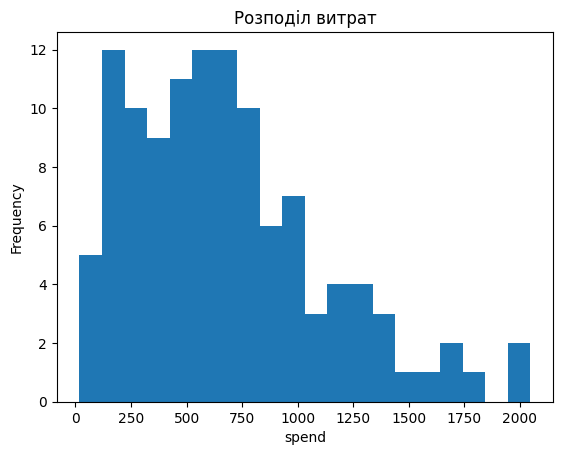

In [28]:
clean["spend"].plot(kind="hist", bins=20, title="Розподіл витрат")
plt.xlabel("spend")
plt.show()

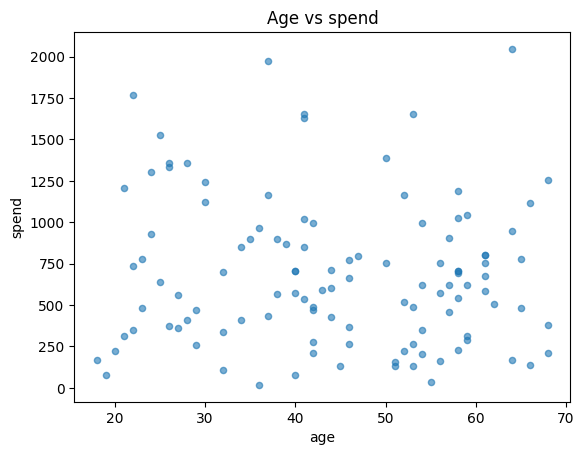

In [29]:
clean.plot.scatter(x="age", y="spend", alpha=0.6, title="Age vs spend")
plt.show()

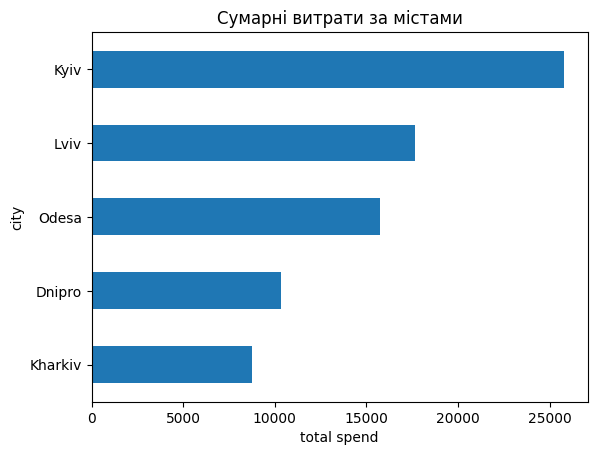

In [30]:
city_summary["total_spend"].sort_values().plot(
    kind="barh",
    title="Сумарні витрати за містами",
)
plt.xlabel("total spend")
plt.show()

## 12. EDA і data leakage

Нижче показано лише **правильну послідовність**: спочатку train/test split, потім статистики preprocessing оцінюються на train.

In [31]:
clean

,customer_id,age,city,segment,signup_date,orders,spend,churn,age_filled,signup_year,signup_month,tenure_days,spend_per_order,share_in_city
0,1001,22.0,Odesa,premium,2024-09-13,4,347.14,0,22.0,2024,9,724,86.785000,0.022074
1,1002,58.0,Lviv,premium,2025-05-31,9,706.18,0,58.0,2025,5,464,78.464444,0.040048
2,1003,52.0,Odesa,standard,2025-03-28,11,1164.91,0,52.0,2025,3,528,105.900909,0.074073
3,1004,40.0,Dnipro,basic,2022-08-04,7,77.99,0,40.0,2022,8,1495,11.141429,0.007553
4,1005,40.0,Odesa,standard,2025-08-14,8,574.75,0,40.0,2025,8,389,71.843750,0.036547
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,1116,47.0,Kyiv,premium,2025-07-02,5,795.16,0,47.0,2025,7,432,159.032000,0.030829
116,1117,19.0,Lviv,premium,2024-04-08,11,79.78,1,19.0,2024,4,882,7.252727,0.004524
117,1118,25.0,Kharkiv,standard,2024-02-27,6,637.44,0,25.0,2024,2,923,106.240000,0.072880
118,1119,30.0,Kharkiv,standard,2023-01-13,7,1243.22,0,30.0,2023,1,1333,177.602857,0.142140


In [32]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    clean,
    test_size=0.2,
    random_state=42,
    stratify=clean["churn"],
)

train_median = train_df["age"].median()
train_age = train_df["age"].fillna(train_median)
test_age = test_df["age"].fillna(train_median)

print("train:", train_df.shape)
print("test:", test_df.shape)
print("Медіана, оцінена лише на train:", train_median)

train: (96, 14)
test: (24, 14)
Медіана, оцінена лише на train: 44.0


# Завдання для студентів

Виконайте завдання нижче самостійно. Після кожного завдання додайте короткий висновок у Markdown-комірці: **що саме було виявлено і чому це важливо**.

## Завдання 1. Первинний аудит даних
1. Визначте розмір `df`.
2. Виведіть типи всіх стовпців.
3. Порахуйте кількість унікальних значень у кожному стовпці.
4. Визначте частку пропусків.
5. Назвіть щонайменше три потенційні проблеми якості даних.

In [33]:
# TODO: Ваш код для завдання 1

print(f"Розмір таблиці: {df.shape[0]} рядків і {df.shape[1]} стовпців")

print("\nТипи даних:")
print(df.dtypes)

print("\nКількість унікальних значень без пропусків:")
print(df.nunique())

missing = pd.DataFrame({
    "Кількість пропусків": df.isna().sum(),
    "Частка пропусків, %": df.isna().mean() * 100
})

display(missing.round(2))

print("Повних дублікатів:", df.duplicated().sum())
print("Повторів customer_id:", df.duplicated("customer_id").sum())
print("Від’ємних spend:", df["spend"].lt(0).sum())
print("Варіанти назв міст:", df["city"].unique())

print(
    "\nПотенційні проблеми якості: пропуски, дублікати, "
    "неузгоджене написання міст і від’ємні витрати"
)

Розмір таблиці: 122 рядків і 8 стовпців

Типи даних:
customer_id             int64
age                   float64
city                   object
segment                object
signup_date    datetime64[ns]
orders                  int64
spend                 float64
churn                   int64
dtype: object

Кількість унікальних значень без пропусків:
customer_id    120
age             45
city             7
segment          3
signup_date    117
orders          14
spend          116
churn            2
dtype: int64


,Кількість пропусків,"Частка пропусків, %"
customer_id,0,0.00
age,3,2.46
city,0,0.00
segment,1,0.82
signup_date,0,0.00
orders,0,0.00
spend,4,3.28
churn,0,0.00


Повних дублікатів: 2
Повторів customer_id: 2
Від’ємних spend: 1
Варіанти назв міст: ['Odesa' 'Lviv' 'Dnipro' 'Kyiv' ' kyiv ' 'LVIV' 'Kharkiv']

Потенційні проблеми якості: пропуски, дублікати, неузгоджене написання міст і від’ємні витрати


У таблиці 122 рядки та 8 стовпців. Виявлено пропуски, два дублікати, різне написання назв міст і від’ємні витрати, які можуть спотворювати результати аналізу.

## Завдання 2. Фільтрація
Створіть DataFrame `task2`, який містить клієнтів:
- віком від 30 до 50 років;
- із сегменту `premium` або `standard`;
- з витратами понад 600;
- лише зі стовпцями `customer_id`, `age`, `city`, `segment`, `spend`.

Відсортуйте результат за `spend` за спаданням.

In [37]:
# TODO: Ваш код для завдання 2

filtered_customers = df.loc[
    df["age"].between(30, 50)
    & df["segment"].isin(["premium", "standard"])
    & (df["spend"] > 600),
    ["customer_id", "age", "city", "segment", "spend"]
].sort_values("spend", ascending=False)

display(filtered_customers)

,customer_id,age,city,segment,spend
29,1030,41.0,Odesa,standard,1651.09
84,1085,50.0,Lviv,premium,1386.54
118,1119,30.0,Kharkiv,standard,1243.22
21,1022,37.0,Lviv,premium,1162.84
75,1076,42.0,Kyiv,standard,997.35
43,1044,36.0,Kharkiv,premium,963.23
76,1077,35.0,Kharkiv,standard,898.33
64,1065,39.0,Kyiv,standard,870.96
30,1031,41.0,Kyiv,standard,851.50
65,1066,34.0,Lviv,premium,848.28


Відібрано 16 клієнтів, які відповідають усім умовам. Сортування за спаданням витрат дозволяє першими побачити клієнтів із найбільшими витратами.

## Завдання 3. Очищення
На копії `df` виконайте:
1. видалення повних дублікатів;
2. очищення пробілів і регістру в `city`;
3. заміну від’ємних `spend` на пропуск;
4. підрахунок кількості пропусків після очищення;
5. поясніть, які пропуски ви б видаляли, а які — імпутували.

In [38]:
# TODO: Ваш код для завдання 3

clean_customers = df.copy()
clean_customers = clean_customers.drop_duplicates().copy()

clean_customers["city"] = (
    clean_customers["city"].str.strip().str.title()
)

clean_customers.loc[
    clean_customers["spend"] < 0, "spend"
] = np.nan

print("Розмір після очищення:", clean_customers.shape)

print("\nПропуски після очищення:")
print(clean_customers.isna().sum())

print("\nНазви міст:", clean_customers["city"].unique())

Розмір після очищення: (120, 8)

Пропуски після очищення:
customer_id    0
age            3
city           0
segment        1
signup_date    0
orders         0
spend          5
churn          0
dtype: int64

Назви міст: ['Odesa' 'Lviv' 'Dnipro' 'Kyiv' 'Kharkiv']


Після очищення залишилося 120 рядків, уніфіковано назви міст і замінено від’ємні витрати пропуском. Вік можна заповнити медіаною навчальної вибірки, сегмент — категорією unknown; рядки без витрат можна виключати з аналізу витрат, а для моделі — обґрунтовано заповнювати.

## Завдання 4. Групова аналітика
Для кожного `segment` обчисліть:
- кількість клієнтів;
- середню кількість замовлень;
- медіанні витрати;
- сумарні витрати;
- churn rate.

Відсортуйте сегменти за churn rate від найбільшого до найменшого.

In [39]:
# TODO: Ваш код для завдання 4

segment_summary = (
    clean_customers.groupby("segment", dropna=False)
    .agg(
        customers=("customer_id", "nunique"),
        avg_orders=("orders", "mean"),
        median_spend=("spend", "median"),
        total_spend=("spend", "sum"),
        churn_rate=("churn", "mean")
    )
    .sort_values("churn_rate", ascending=False)
)

display(segment_summary.round(3))

,customers,avg_orders,median_spend,total_spend,churn_rate
segment,,,,,
NaN,1,6.000,777.760,777.76,1.000
standard,43,7.000,503.860,27178.88,0.326
basic,58,6.793,668.135,37335.78,0.241
premium,18,7.389,738.405,12931.55,0.222


Сегмент basic має найбільше клієнтів і найбільші сумарні витрати. Серед відомих сегментів найвищий відтік у standard — 32,6%, найнижчий у premium — 22,2%; група невідомого сегмента містить лише одного клієнта.

## Завдання 5. Ознаки на основі дат
Створіть:
- `signup_year`;
- `signup_quarter`;
- `tenure_days` станом на 07.09.2026.

Після цього визначте, у якому році зареєструвалося найбільше клієнтів.

In [40]:
# TODO: Ваш код для завдання 5

reference_date = pd.Timestamp("2026-09-07")

clean_customers["signup_year"] = (
    clean_customers["signup_date"].dt.year
)

clean_customers["signup_quarter"] = (
    clean_customers["signup_date"].dt.quarter
)

clean_customers["tenure_days"] = (
    reference_date - clean_customers["signup_date"]
).dt.days

display(clean_customers[[
    "customer_id",
    "signup_date",
    "signup_year",
    "signup_quarter",
    "tenure_days"
]].head())

registrations = (
    clean_customers.groupby("signup_year")["customer_id"]
    .nunique()
)

print("Кількість клієнтів за роками:")
print(registrations)

top_years = registrations[
    registrations == registrations.max()
]

print("\nРік або роки з найбільшою кількістю реєстрацій:")
print(top_years)

,customer_id,signup_date,signup_year,signup_quarter,tenure_days
0,1001,2024-09-13,2024,3,724
1,1002,2025-05-31,2025,2,464
2,1003,2025-03-28,2025,1,528
3,1004,2022-08-04,2022,3,1495
4,1005,2025-08-14,2025,3,389


Кількість клієнтів за роками:
signup_year
2022    22
2023    21
2024    37
2025    27
2026    13
Name: customer_id, dtype: int64

Рік або роки з найбільшою кількістю реєстрацій:
signup_year
2024    37
Name: customer_id, dtype: int64


Створено рік і квартал реєстрації та тривалість перебування клієнта. Найбільше реєстрацій було у 2024 році — 37; ці ознаки корисні для порівняння клієнтів за часом реєстрації.

## Завдання 6. Об’єднання таблиць
Створіть окрему таблицю `segment_info` з полями:
- `segment`;
- `discount_rate`;
- `support_level`.

Об’єднайте її з очищеним набором через `merge`. Обов’язково використайте `validate` і поясніть, який тип зв’язку очікується.

In [41]:
# TODO: Ваш код для завдання 6

segment_info = pd.DataFrame({
    "segment": ["basic", "standard", "premium"],
    "discount_rate": [0.00, 0.05, 0.10],
    "support_level": [
        "Базовий",
        "Стандартний",
        "Пріоритетний"
    ]
})

customers_with_support = clean_customers.merge(
    segment_info,
    on="segment",
    how="left",
    validate="many_to_one",
    indicator=True
)

display(customers_with_support.head())

print("Результат об’єднання:")
print(customers_with_support["_merge"].value_counts())

print("\nКлієнти без відповідності в довіднику:")
display(customers_with_support.loc[
    customers_with_support["_merge"] == "left_only",
    ["customer_id", "segment", "discount_rate", "support_level"]
])

,customer_id,age,city,segment,signup_date,orders,spend,churn,signup_year,signup_quarter,tenure_days,discount_rate,support_level,_merge
0,1001,22.0,Odesa,premium,2024-09-13,4,347.14,0,2024,3,724,0.10,Пріоритетний,both
1,1002,58.0,Lviv,premium,2025-05-31,9,706.18,0,2025,2,464,0.10,Пріоритетний,both
2,1003,52.0,Odesa,standard,2025-03-28,11,1164.91,0,2025,1,528,0.05,Стандартний,both
3,1004,40.0,Dnipro,basic,2022-08-04,7,77.99,0,2022,3,1495,0.00,Базовий,both
4,1005,40.0,Odesa,standard,2025-08-14,8,574.75,0,2025,3,389,0.05,Стандартний,both


Результат об’єднання:
_merge
both          119
left_only       1
right_only      0
Name: count, dtype: int64

Клієнти без відповідності в довіднику:


,customer_id,segment,discount_rate,support_level
66,1067,NaN,NaN,NaN


Використано зв’язок «багато до одного», перевірений через validate: багатьом клієнтам відповідає один запис сегмента в довіднику. Відповідність знайдено для 119 клієнтів, один залишився без неї через пропущений сегмент.

## Завдання 7. Pivot table
Побудуйте `pivot_table`, де:
- рядки — `city`;
- стовпці — `segment`;
- значення — медіана `spend`.

Визначте комбінацію місто–сегмент із найбільшою медіаною витрат.

In [42]:
# TODO: Ваш код для завдання 7

spend_pivot = clean_customers.pivot_table(
    index="city",
    columns="segment",
    values="spend",
    aggfunc="median"
)

display(spend_pivot.round(2))

medians = spend_pivot.stack().dropna()
best_city, best_segment = medians.idxmax()

print("Місто:", best_city)
print("Сегмент:", best_segment)
print("Найбільша медіана витрат:", round(medians.max(), 2))

segment,basic,premium,standard
city,,,
Dnipro,703.23,1254.48,456.84
Kharkiv,533.90,762.48,767.88
Kyiv,663.68,701.06,727.90
Lviv,679.78,777.23,425.10
Odesa,672.59,639.00,489.18


Місто: Dnipro
Сегмент: premium
Найбільша медіана витрат: 1254.48


Найбільша медіана витрат у комбінації Dnipro–premium — 1254,48. Зведена таблиця дозволяє порівнювати типові витрати між містами та сегментами.

## Завдання 8. Візуалізація
Побудуйте щонайменше три різні графіки:
1. розподіл `age`;
2. boxplot `spend` за сегментами;
3. churn rate за містами.

Для кожного графіка напишіть 1–2 речення інтерпретації.

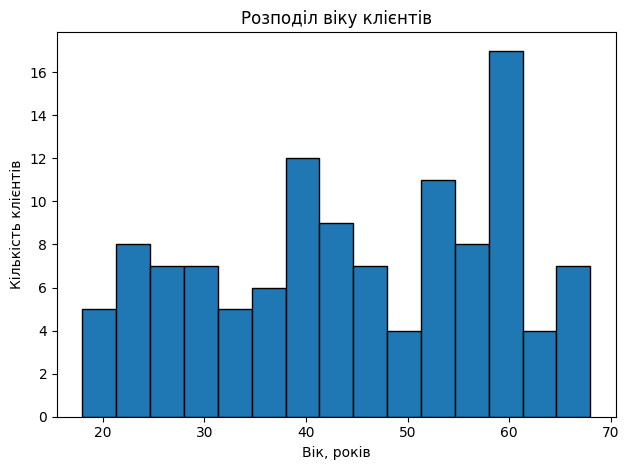

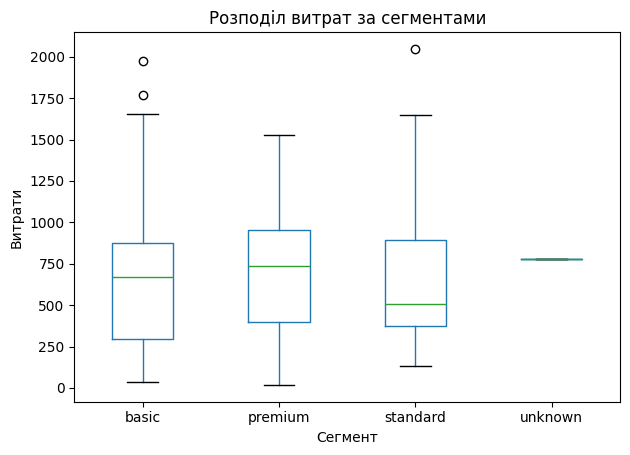

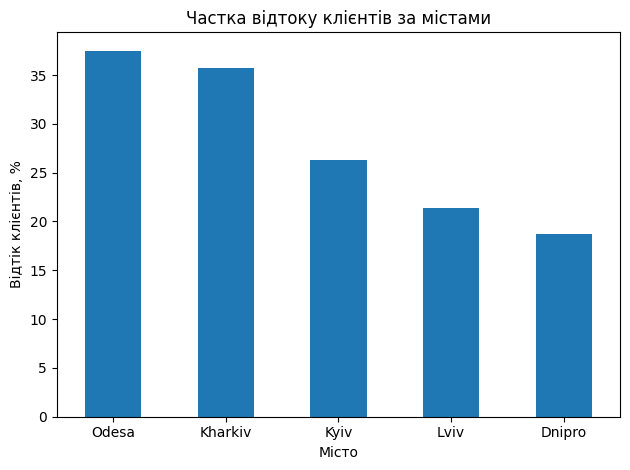

In [43]:
# TODO: Ваш код для завдання 8

clean_customers["age"].plot(
    kind="hist",
    bins=15,
    edgecolor="black",
    title="Розподіл віку клієнтів"
)

plt.xlabel("Вік, років")
plt.ylabel("Кількість клієнтів")
plt.tight_layout()
plt.show()

clean_customers.assign(
    segment=clean_customers["segment"].fillna("unknown")
).boxplot(
    column="spend",
    by="segment",
    grid=False
)

plt.title("Розподіл витрат за сегментами")
plt.suptitle("")
plt.xlabel("Сегмент")
plt.ylabel("Витрати")
plt.tight_layout()
plt.show()

city_churn = (
    clean_customers.groupby("city")["churn"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

city_churn.plot(
    kind="bar",
    title="Частка відтоку клієнтів за містами"
)

plt.xlabel("Місто")
plt.ylabel("Відтік клієнтів, %")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

1. Вік клієнтів охоплює діапазон від 18 до 68 років, тому набір представляє різні вікові групи.
2. У premium медіана витрат вища, ніж у basic та standard. Окремі високі значення потребують перевірки.
3. Найбільший відтік в Odesa — 37,5%, найменший у Dnipro — 18,75%, що показує відмінності між містами.

## Завдання 9. Викиди
За правилом IQR знайдіть потенційні викиди `spend`.

Далі порівняйте середнє та медіану `spend` до і після **тимчасового** виключення цих рядків. Не видаляйте викиди з фінального DataFrame автоматично. Поясніть, чому.

In [44]:
# TODO: Ваш код для завдання 9

q1 = clean_customers["spend"].quantile(0.25)
q3 = clean_customers["spend"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outlier_mask = (
    (clean_customers["spend"] < lower)
    | (clean_customers["spend"] > upper)
)

spend_outliers = clean_customers.loc[outlier_mask].copy()

customers_without_outliers = clean_customers.loc[
    ~outlier_mask
].copy()

print(f"Межі IQR: [{lower:.2f}; {upper:.2f}]")
print("Кількість потенційних викидів:", len(spend_outliers))

display(spend_outliers[[
    "customer_id", "city", "segment", "spend"
]])

comparison = pd.DataFrame({
    "До виключення":
        clean_customers["spend"].agg(["mean", "median"]),
    "Після тимчасового виключення":
        customers_without_outliers["spend"].agg(["mean", "median"])
})

display(comparison.round(2))

Межі IQR: [-480.70; 1729.40]
Кількість потенційних викидів: 3


,customer_id,city,segment,spend
6,1007,Odesa,basic,1771.49
34,1035,Lviv,standard,2046.77
67,1068,Kyiv,basic,1972.21


,До виключення,Після тимчасового виключення
mean,680.21,646.73
median,623.25,612.16


Виявлено 3 потенційні викиди: без них середнє зменшилося з 680,21 до 646,73, медіана — з 623,25 до 612,16. Автоматично видаляти їх не слід, оскільки великі витрати можуть бути реальними.

## Завдання 10. Підсумковий EDA
Підготуйте короткий аналітичний висновок за набором даних. Він має містити:
- розмір і структуру даних;
- проблеми якості;
- 3–5 ключових статистичних спостережень;
- щонайменше 2 візуальні спостереження;
- потенційні ознаки для ML-моделі прогнозування `churn`;
- ризики data leakage;
- план preprocessing перед моделюванням.

In [45]:
# TODO: За потреби додайте код для підсумкового аналізу

summary = pd.Series({
    "Кількість клієнтів":
        clean_customers["customer_id"].nunique(),
    "Середній вік":
        clean_customers["age"].mean(),
    "Середня кількість замовлень":
        clean_customers["orders"].mean(),
    "Середні витрати":
        clean_customers["spend"].mean(),
    "Медіанні витрати":
        clean_customers["spend"].median(),
    "Частка відтоку, %":
        clean_customers["churn"].mean() * 100
})

display(summary.round(2))

print("\nПоказники за сегментами:")
display(segment_summary.round(3))

print("\nВідтік за містами, %:")
display(city_churn.round(2))

print("\nВплив потенційних викидів:")
display(comparison.round(2))

,0
Кількість клієнтів,120.00
Середній вік,44.44
Середня кількість замовлень,6.95
Середні витрати,680.21
Медіанні витрати,623.25
"Частка відтоку, %",27.50



Показники за сегментами:


,customers,avg_orders,median_spend,total_spend,churn_rate
segment,,,,,
NaN,1,6.000,777.760,777.76,1.000
standard,43,7.000,503.860,27178.88,0.326
basic,58,6.793,668.135,37335.78,0.241
premium,18,7.389,738.405,12931.55,0.222



Відтік за містами, %:


,churn
city,
Odesa,37.50
Kharkiv,35.71
Kyiv,26.32
Lviv,21.43
Dnipro,18.75



Вплив потенційних викидів:


,До виключення,Після тимчасового виключення
mean,680.21,646.73
median,623.25,612.16


Проаналізовано таблицю зі 122 рядків і 8 стовпців, яка містить числові, категоріальні ознаки та дату реєстрації. Після видалення дублікатів залишилося 120 клієнтів; виправлено назви міст і від’ємні витрати, виявлено пропуски.

Середній вік становить 44,44 року, середня кількість замовлень — 6,95, середні витрати — 680,21, медіанні — 623,25, відтік — 27,5%. Графіки показують вищу медіану витрат у premium та найбільший відтік в Odesa.

Для прогнозування churn можна використати вік, місто, сегмент, замовлення, витрати й ознаки реєстрації, доступні на момент прогнозу. Перед моделюванням потрібно розділити дані, обробити пропуски, закодувати категорії та за потреби масштабувати числа. Статистики обробки слід визначати лише на навчальній вибірці, щоб уникнути витоку даних.

## Критерії самоперевірки

Робота виконана якісно, якщо:
- код запускається послідовно без помилок;
- вихідний DataFrame не змінюється випадково через неявні присвоєння;
- для вибірки за умовами використано `loc`;
- пропуски й дублікати не обробляються без пояснення;
- `merge` перевіряє очікувану кардинальність через `validate`;
- графіки мають назви та зрозумілі осі;
- висновки містять інтерпретацію, а не лише перелік чисел;
- при переході до ML враховано ризик витоку даних.